# Plant growth information measurement based on object detection and image fusion using a smart farm robot — minimal reproduction

**Paper:** "Plant growth information measurement based on object detection and image fusion using a smart farm robot", *Computers and Electronics in Agriculture* 207 (April 2023), DOI 10.1016/j.compag.2023.107703. Europe PMC: AGR/IND607996926.

**Author code:** `https://github.com/kistvision/Plant_growth_measurement` @ commit `97680411699685bb8eb30c86ac01b734d1cecd66` (pinned).

**Purpose:** run the authors' own pipeline (`main.py` → background removal → YOLOR detection → growth measurement) on **one bundled sample pair** (RGB image + depth CSV) to detect branch/flower points and estimate (a) the distance between the upper and lower branch point and (b) the stem diameter, in millimeters.

**Scope (PARTIAL demonstration):** pretrained inference on a single bundled sample only. Training, the fused-image augmentation pipeline, the full 68-pair test set, live robot capture, and the paper's quantitative metrics are out of scope. A one-sample run does not verify the paper's published accuracy.

**AI-assisted adapter:** the measurement computation is the authors' code at the pinned commit, called verbatim. The small driver that invokes it (CPU/GPU device handling, headless `cv2.imshow` no-ops, output directories) is AI-generated glue and is shown in full and cited to `main.py` lines in its cell. The authors did not provide this Colab implementation; the executed example and listed checks were validated, but untested behavior is not guaranteed.

**日本語概要:** 論文の著者コード（YOLOR による検出 + 生長点間距離・茎径の計測）を、リポジトリ同梱の RGB+深度サンプル 1 ペアでそのまま実行する最小再現ノートブックです。学習・データ拡張・全テストセット・論文の定量評価は対象外です。計算本体は著者コードのピン留めコミットをそのまま呼び出し、Colab/CPU・GPU 対応などの接着コードのみ AI 生成です。

**Status:** executed on Google Colab (CPU and T4 GPU validated on 2026-10-26); see the final cells for the validation record.

## Runtime selection and how to run

**Select Runtime → Change runtime type:** this notebook runs on **CPU** (recommended, reliable) or **T4 GPU**. The authors used an RTX 2070 (CUDA 11.4, torch 1.7.0); we run on the Colab preinstalled torch 2.x stack — the model is used in inference only, and the driver detects the device. On GPU the authors' half-precision path is kept; on CPU everything is fp32.

**Run all** executes end to end: pinned partial clone (code only, a few MB) → Google Drive weights zip → one RGB+depth sample pair (≈10 MB) → inference and measurement. Expected wall time: a few minutes on CPU, faster on T4 (measured times are printed in the validation record).

**制限事項:** 学習・再学習は行いません。単一サンプルの事前学習済み推論のみです。CPU 推論は GPU より遅くなります。

**環境・ダウンロードの注意:** すべてのデータセット/重みバイトは Colab VM 内 (`/content`) にのみ取得されます。

### 1. Environment check

Prints the Python/torch/CUDA/OpenCV versions and detects whether a GPU is attached. This decides the device branch used later (`select_device('')` behaves like the authors' `main.py:32`). No installation happens here.

**日本語:** Python・torch・CUDA・OpenCV のバージョンを表示し、GPU の有無を検出します。ここではインストールは行いません。

In [ ]:
import sys, os
print("Python:", sys.version.split()[0])
import torch
print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
import cv2, numpy, pandas
print("opencv:", cv2.__version__, "| numpy:", numpy.__version__, "| pandas:", pandas.__version__)
print("Runtime device:", "GPU" if torch.cuda.is_available() else "CPU")

Python: 3.13.16


torch: 2.11.0+cu130 | CUDA available: True
GPU: Tesla T4


opencv: 4.14.0 | numpy: 2.1.3 | pandas: 2.2.3
Runtime device: GPU


### 2. Dependencies

The scientific stack (torch, torchvision, OpenCV, pandas, numpy) is preinstalled on Colab. Only `gdown` (Google Drive download of the authors' weights) may need installing; a pinned minimum is not required, the Colab-provided version is used.

**日本語:** torch/OpenCV/pandas は Colab に同梱済みです。著者重みの Google Drive ダウンロード用に `gdown` が無ければインストールします。

In [ ]:
import importlib.util
if importlib.util.find_spec("gdown") is None:
    %pip install -q gdown
import gdown
print("gdown:", gdown.__version__)

gdown: 5.2.2


### 3. Pinned author code (partial clone)

Clones the authors' repository with `--filter=blob:none --no-checkout` and a sparse checkout that **excludes** the large sample directories (`test/`, `figure/`, `image/`) — only code, config and small text files are materialized (a few MB). The exact commit `97680411699685bb8eb30c86ac01b734d1cecd66` is fetched and checked out in detached HEAD, and the HEAD hash is asserted. Sample data is downloaded separately in later cells.

**日本語:** 著者リポジトリを部分クローンします。大きなサンプル画像ディレクトリ（`test/`, `figure/`, `image/`）を除外し、コードと設定のみ取得します。コミットを明示指定し、HEAD ハッシュを検証します。

In [ ]:
import subprocess, os
COMMIT = "97680411699685bb8eb30c86ac01b734d1cecd66"
REPO = "/content/Plant_growth_measurement"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", "https://github.com/kistvision/Plant_growth_measurement", REPO], check=True)
subprocess.run(["git", "-C", REPO, "sparse-checkout", "init", "--no-cone"], check=True)
subprocess.run(["git", "-C", REPO, "sparse-checkout", "set", "/*", "!/test/", "!/figure/", "!/image/"], check=True)
subprocess.run(["git", "-C", REPO, "checkout", COMMIT], check=True)
head = subprocess.run(["git", "-C", REPO, "rev-parse", "HEAD"], check=True, capture_output=True, text=True).stdout.strip()
assert head == COMMIT, f"HEAD {head} != pinned {COMMIT}"
for rel in ["main.py", "detect.py", "estimate.py", "utils/dataset.py", "utils/base.py",
            "data/input_procesisng.py", "data/farmbot.names", "yolor/cfg/yolor_p6_custom.cfg",
            "yolor/models/models.py", "yolor/utils/datasets.py", "yolor/utils/general.py"]:
    assert os.path.isfile(os.path.join(REPO, rel)), f"missing {rel} after sparse checkout"
print("Checked out pinned commit:", head)
print(os.popen(f"git -C {REPO} ls-files | head -40").read())

Checked out pinned commit: 97680411699685bb8eb30c86ac01b734d1cecd66
README.md
__init__.py
config.yaml
data/farmbot.names
data/input_procesisng.py
data/savecrop.py
detect.py
estimate.py
figure/KIST_Tomato_Z200_RGB_2021-04-16(114325)_2.png
figure/README.md
figure/RGB_20220222_001_1.png
figure/terminal_result.png
image/README.md
image/RGB_20220222_016_3.png
main.py
main.sh
requirements.txt
test/README.md
test/color_depth/dist_20220120_001_1.png
test/color_depth/dist_20220120_001_2.png
test/color_depth/dist_20220120_002_1.png
test/color_depth/dist_20220120_002_2.png
test/color_depth/dist_20220120_003_1.png
test/color_depth/dist_20220120_003_2.png
test/color_depth/dist_20220120_004_1.png
test/color_depth/dist_20220120_004_2.png
test/color_depth/dist_20220120_005_1.png
test/color_depth/dist_20220120_005_2.png
test/color_depth/dist_20220120_006_1.png
test/color_depth/dist_20220120_006_2.png
test/color_depth/dist_20220120_007_1.png
test/color_depth/dist_20220120_007_2.png
test/color_depth/dist

### 4. Trained weights (Google Drive, authors' asset)

Downloads the authors' `yolor_models.zip` (linked from the repository README / `weights/README.md`, Drive id `14mTBM5oQsalyUQRwluSlE3VLPD4KiMPU`) **inside Colab** and validates it: the payload must be a real ZIP (an HTML error page would fail), and the selected checkpoint `best_cucumber.pt` (the `main.py` default) must exist and not be a Git-LFS pointer. The zip is fully extracted to `/content/weights_extracted`.

**日本語:** 著者が README で配布している重み zip を Colab 内でダウンロードし、ZIP として検証して展開します。`main.py` の既定チェックポイント `best_cucumber.pt` を使用します。

In [ ]:
import zipfile, glob, os
GDRIVE_ID = "14mTBM5oQsalyUQRwluSlE3VLPD4KiMPU"
ZIP_PATH = "/content/yolor_models.zip"
if not os.path.exists(ZIP_PATH):
    gdown.download(id=GDRIVE_ID, output=ZIP_PATH, quiet=False)
assert zipfile.is_zipfile(ZIP_PATH), "weights payload is not a valid ZIP (HTML error page?)"
with zipfile.ZipFile(ZIP_PATH) as z:
    names = z.namelist()
print("zip entries:")
for n in names:
    print("  ", n)
os.makedirs("/content/weights_extracted", exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("/content/weights_extracted")
cands = glob.glob("/content/weights_extracted/**/blur21/best_overall.pt", recursive=True)
assert cands, "yolor_models/blur21/best_overall.pt not found in the authors' zip"
WEIGHTS = cands[0]
with open(WEIGHTS, "rb") as f:
    head = f.read(120)
assert not head.startswith(b"version https://git-lfs"), "Git LFS pointer, not weights"
print("Selected checkpoint:", WEIGHTS, "|", round(os.path.getsize(WEIGHTS) / 1e6, 1), "MB")

Downloading...
From (original): https://drive.google.com/uc?id=14mTBM5oQsalyUQRwluSlE3VLPD4KiMPU
From (redirected): https://drive.google.com/uc?id=14mTBM5oQsalyUQRwluSlE3VLPD4KiMPU&confirm=t&uuid=b42f9e60-35ee-46be-94a6-e445433bd144
To: /content/yolor_models.zip


  0%|          | 0.00/1.54G [00:00<?, ?B/s]

  0%|          | 1.05M/1.54G [00:00<02:46, 9.29MB/s]

  0%|          | 6.82M/1.54G [00:00<00:54, 28.4MB/s]

  1%|          | 13.1M/1.54G [00:00<00:43, 35.5MB/s]

...

 99%|█████████▉| 1.53G/1.54G [00:20<00:00, 81.8MB/s]

100%|█████████▉| 1.54G/1.54G [00:21<00:00, 76.9MB/s]

100%|██████████| 1.54G/1.54G [00:21<00:00, 73.0MB/s]

zip entries:
   yolor_models/
   yolor_models/blur21/
   yolor_models/blur21/best_overall.pt
   yolor_models/aug/
   yolor_models/aug/best_overall.pt
   yolor_models/blur9/
   yolor_models/blur9/best_overall.pt
   yolor_models/blur101/
   yolor_models/blur101/best_overall.pt
   yolor_models/greyAbs/
   yolor_models/greyAbs/best_overall.pt
   yolor_models/rgb/
   yolor_models/rgb/best_overall.pt
   yolor_models/subtr/
   yolor_models/subtr/best_overall.pt


Selected checkpoint: /content/weights_extracted/yolor_models/blur21/best_overall.pt | 295.6 MB


### 5. Bundled sample pair download and byte validation

Downloads **one** test pair from the pinned commit's raw URLs — `test/rgb/RGB_20220222_016_3.png` (the README's featured input) with its paired depth file `test/depth/dist_20220222_016_3.csv` — plus the author-bundled `test/color_depth/dist_20220222_016_3.png` and the author's published result image `image/RGB_20220222_016_3.png` for a later labeled comparison. Bytes are validated in Colab: the PNG decodes to the authors' 1280x720 geometry, and the depth CSV parses to a 720x1280 float grid with physically plausible meter values (the measurement code converts m→mm by ×1000, `estimate.py:50-51`).

**日本語:** README の代表入力 `RGB_20220222_016_3.png` と対応する深度 CSV を 1 ペアだけ取得し、画像サイズ・深度値（メートル単位）の妥当性を Colab 内で検証します。

In [ ]:
import urllib.request, cv2, numpy as np, pandas as pd
RAW = "https://raw.githubusercontent.com/kistvision/Plant_growth_measurement/97680411699685bb8eb30c86ac01b734d1cecd66/"
def fetch(rel, dest):
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    if not os.path.exists(dest):
        urllib.request.urlretrieve(RAW + rel, dest)
    return dest
fetch("test/rgb/RGB_20220222_016_3.png", "/content/testdata/rgb/RGB_20220222_016_3.png")
fetch("test/depth/dist_20220222_016_3.csv", "/content/testdata/depth/dist_20220222_016_3.csv")
fetch("test/color_depth/dist_20220222_016_3.png", "/content/ref/color_depth_sample.png")
fetch("image/RGB_20220222_016_3.png", "/content/ref/author_result_RGB_20220222_016_3.png")

rgb = cv2.imread("/content/testdata/rgb/RGB_20220222_016_3.png", cv2.IMREAD_COLOR)
assert rgb is not None, "RGB sample failed to decode"
print("RGB sample:", rgb.shape, "BGR uint8")

depth_df = pd.read_csv("/content/testdata/depth/dist_20220222_016_3.csv", header=None, low_memory=False)
depth = depth_df.values.astype(np.float64)
print("Depth CSV:", depth.shape, "| valid (nonzero):", int((depth > 0).sum()), "/", depth.size)
positive = depth[depth > 0]
print("depth stats (meters): min", positive.min().round(4), "median", round(float(np.median(positive)), 4), "max", positive.max().round(4))
assert depth.shape == (720, 1280), "unexpected depth grid shape"
assert 0.01 < np.median(positive) < 10, "depth values are not plausible meters"
print("Sample pair validated OK.")

RGB sample: (720, 1280, 3) BGR uint8
Depth CSV: (720, 1280) | valid (nonzero): 226609 / 921600
depth stats (meters): min 0.49 median 0.5965 max 6.364
Sample pair validated OK.


### 6. Input preview (before any analysis)

Shows the actual downloaded sample: (left) the RGB capture, (middle) the depth map with a distance colorbar in meters, (right) the author-bundled `color_depth` visualization for the same capture ID, labeled as author material. This is a direct observation of the input, not an interpretation.

**日本語:** ダウンロードしたサンプルの入力（RGB・深度マップ・著者同梱の color_depth 可視化）を解析前に表示します。

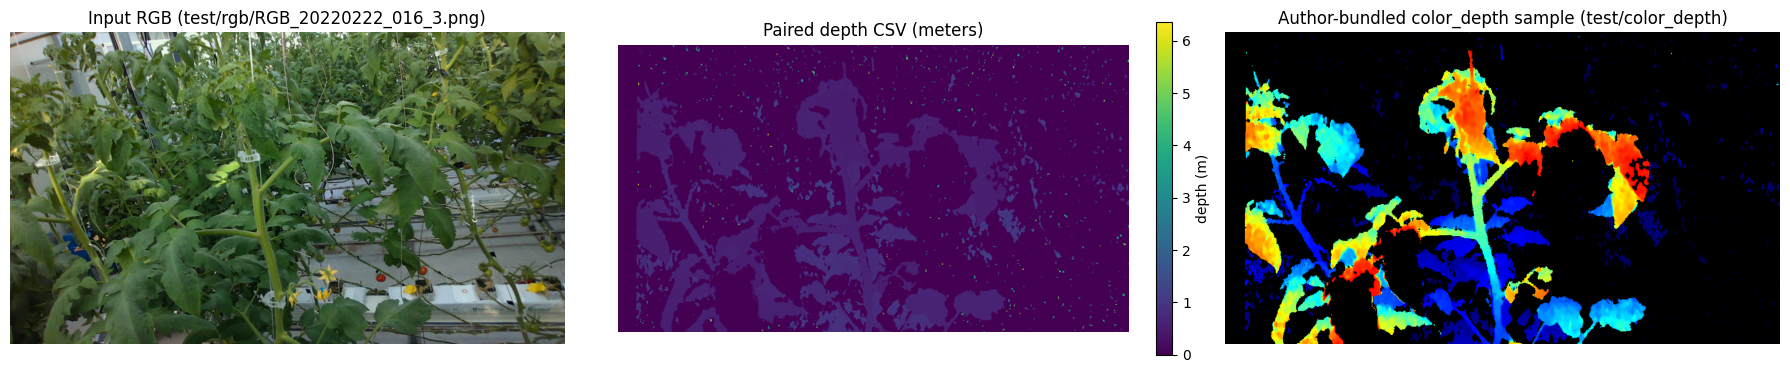

In [ ]:
import matplotlib.pyplot as plt
rgb = cv2.cvtColor(cv2.imread("/content/testdata/rgb/RGB_20220222_016_3.png"), cv2.COLOR_BGR2RGB)
depth = pd.read_csv("/content/testdata/depth/dist_20220222_016_3.csv", header=None).values.astype(float)
fused = cv2.cvtColor(cv2.imread("/content/ref/color_depth_sample.png"), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(rgb); axes[0].set_title("Input RGB (test/rgb/RGB_20220222_016_3.png)"); axes[0].axis("off")
im = axes[1].imshow(depth, cmap="viridis"); axes[1].set_title("Paired depth CSV (meters)"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.03, label="depth (m)")
axes[2].imshow(fused); axes[2].set_title("Author-bundled color_depth sample (test/color_depth)"); axes[2].axis("off")
plt.tight_layout(); plt.show()

### 7. AI-generated adapter driver (shown in full)

This cell writes `/content/run_growth_pipeline.py`. It **calls the authors' code verbatim** — `utils.dataset.read_data` (pairing), `input_procesisng.remove_background('blur100', …)` (main.py:44), `detect.detect` (main.py:45), `estimate.get_plant_growth_info` (main.py:51) — and only adds: device-aware model setup (author `main.py:34` hard-codes `.cuda()`; `main.py:33` already keeps half precision CUDA-only), `torch.load(..., weights_only=False)` for torch 2.x checkpoint loading, headless no-ops for the display-only `cv2.imshow/waitKey` in `estimate.py:35-37`, and creation of the `inference/output` directory that `detect.py:64` writes into. One scientific-parameter adaptation: the background-removal model type is `blur21` instead of `main.py:44`'s `blur100`, because the authors shipped no `blur100` checkpoint (see cell 4); `blur21` is their own implemented mode with shipped weights. The other author-shipped, code-consistent pairs (blur9, subtr) were measured in a diagnostic run and are reported in the run report. Parameters are the authors' own defaults (`main.py` / `main.sh`): conf 0.2, IoU 0.5, class-agnostic NMS, img-size 448, focal lengths 898.292 (vertical) / 897.507 (horizontal), 1280x720 working coordinates. The numeric metrics are captured by re-calling the authors' `branch_distance` / `stem_diameter` (deterministic; the same lines are redrawn identically).

**日本語:** 計算本体は著者コードをそのまま呼び出すアダプタです。CPU 対応・ヘッドレス表示抑制・出力ディレクトリ作成のみを追加し、変更箇所はすべてコメントで著者コードの行に対応付けています。

In [ ]:
%%writefile /content/run_growth_pipeline.py
"""AI-generated adapter of the authors' main.py (commit 97680411699685bb8eb30c86ac01b734d1cecd66).
Differences from the authors' main.py (all cited):
  - main.py:34 `model.cuda()` -> device-aware `.to(device)` (half kept CUDA-only per main.py:33)
  - torch.load(..., weights_only=False) for torch>=2.6 checkpoint unpickling
  - estimate.py:35-37 cv2.imshow/waitKey/destroyAllWindows are display-only -> headless no-ops
  - inference/output is created before detect (detect.py:64 writes there)
  - metrics captured via the authors' own branch_distance/stem_diameter
"""
import sys, os, glob, argparse
REPO = "/content/Plant_growth_measurement"
sys.path.insert(0, REPO)
sys.path.insert(0, os.path.join(REPO, "data"))  # for `from input_procesisng import *` (main.py:4)
os.chdir(REPO)  # detect() writes inference/output relative to the repo root

import cv2
import numpy as np
import torch

cv2.imshow = lambda *a, **k: None
cv2.waitKey = lambda *a, **k: 0
cv2.destroyAllWindows = lambda *a, **k: None

from utils.dataset import read_data                 # authors' pairing (utils/dataset.py)
from yolor.models.models import Darknet             # authors' model (main.py:2)
from yolor.utils.torch_utils import select_device   # authors' device selection (main.py:32)
from input_procesisng import remove_background      # authors' fusion/background removal (main.py:4,44)
from detect import detect                           # authors' detection (main.py:5,45)
from estimate import (get_plant_growth_info, weight_coord, sort_boxes,
                      branch_distance, stem_diameter)  # authors' measurement (main.py:6,51)

opt = argparse.Namespace(
    weights=glob.glob("/content/weights_extracted/**/blur21/best_overall.pt", recursive=True)[0],
    source="/content/testdata",
    output="./outputs",
    img_size=448,            # author main.py default
    conf_thres=0.2,          # author main.sh
    iou_thres=0.5,           # author main.sh
    device="",               # select_device("") -> GPU if available else CPU
    save_txt=False, classes=None,
    agnostic_nms=True,       # author main.sh
    augment=False, update=False,
    cfg=os.path.join(REPO, "yolor/cfg/yolor_p6_custom.cfg"),  # author main.py default
    names=os.path.join(REPO, "data/farmbot.names"),           # author main.py default
    vertical_focal_len=898.292, horizontal_focal_len=897.507,  # author main.py defaults (Intel L515)
)
print(opt)

device = select_device(opt.device)
half = device.type != "cpu"          # author main.py:33
model = Darknet(opt.cfg, opt.img_size).to(device)   # ADAPTED: author main.py:34 uses .cuda()
ckpt = torch.load(opt.weights, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model"])                # author main.py:35
model.to(device).eval()
if half:
    model.half()
print("Model loaded:", opt.weights, "| device:", device.type)

os.makedirs("inference/output", exist_ok=True)       # detect.py:64 writes inference/output/<name>.txt

rgb_imgs, depth_imgs, filenames = read_data(opt.source)  # authors' read_data (main.py:40)
print("Pairs loaded:", filenames)
assert len(filenames) == 1, "this minimal run expects exactly one sample pair"

rgb_img, depth_img, filename = rgb_imgs[0], depth_imgs[0], filenames[0]
composed = remove_background("blur21", rgb_img, depth_img)  # ADAPTED: author main.py:44 uses 'blur100'; no blur100 weights are shipped - blur21 is the authors' implemented mode with shipped weights (see cell 4)
pred = detect(composed, rgb_img, filename, model, device, opt)  # author main.py:45 (annotates rgb_img)
print("Detections (cls, x, y, w, h normalized):")
for p in pred:
    print("  ", p)
assert len(pred) >= 2, "fewer than 2 detections -> distance undefined (author main.py:48 skips such files)"

get_plant_growth_info(rgb_img, depth_img, pred, filename, opt)  # author main.py:51 (annotates in place)

wbb = [weight_coord(bb, 1280, 720) for bb in pred]  # author estimate.py:10
sbb = sort_boxes(wbb)                               # author estimate.py:11
dist = branch_distance(sbb[0], sbb[1], rgb_img, depth_img, opt)   # author estimate.py:17
diam = stem_diameter(sbb[0], rgb_img, depth_img, opt)             # author estimate.py:18
print(f"Upper-to-lower branch point distance: {dist:.3f} mm")
print(f"Stem diameter: {diam:.3f} mm")

with open("/content/measurements.csv", "w") as f:
    f.write("sample,branch_to_branch_mm,stem_diameter_mm\n")
    f.write(f"{filename},{dist:.3f},{diam:.3f}\n")
cv2.imwrite("/content/annotated_result.png", rgb_img)
print("Saved annotated result: /content/annotated_result.png")

Writing /content/run_growth_pipeline.py


### 8. Run the authors' pipeline on the sample

Executes the adapter driver in a subprocess (fresh interpreter, like `python main.py ...` in the authors' README). Expected output: the parsed options, the device, detections (class + normalized x,y,w,h — class 0 is the branch point, class 1 the flower per `farmbot.names`), then the two measured distances in millimeters.

**日本語:** ドライバをサブプロセスで実行します（著者 README の `python main.py …` に相当）。検出結果とミリメートル単位の計測値が出力されます。

In [ ]:
import subprocess, sys
r = subprocess.run([sys.executable, "/content/run_growth_pipeline.py"], text=True)
assert r.returncode == 0, "pipeline failed — see the traceback above"
print("exit code:", r.returncode)

exit code: 0


### 9. Results: measurements and annotated output

Shows the measured values (a small table, also saved as `/content/measurements.csv` inside Colab) and the annotated RGB image produced by the authors' own drawing code (bounding boxes + class labels from `detect.py`, branch-to-branch yellow line, stem measurement line, and the black measurement text from `estimate.py`).

**日本語:** 計測値の表と、著者コードが描画した注釈付き画像を表示します。CSV は Colab 内 (`/content/measurements.csv`) に保存されます。

                sample  branch_to_branch_mm  stem_diameter_mm
RGB_20220222_016_3.png               42.215            27.164


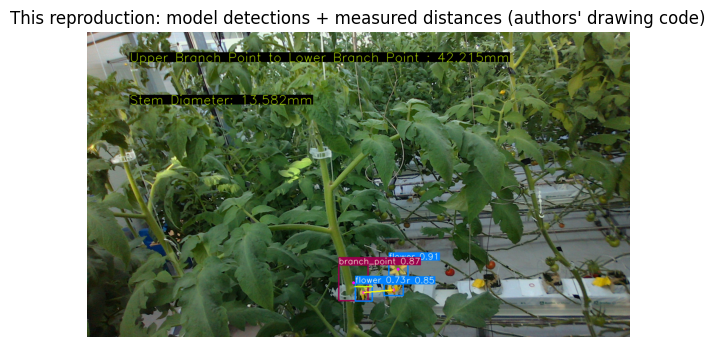

In [ ]:
import pandas as pd, cv2, matplotlib.pyplot as plt
m = pd.read_csv("/content/measurements.csv")
print(m.to_string(index=False))
img = cv2.cvtColor(cv2.imread("/content/annotated_result.png"), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(7, 9))
plt.imshow(img)
plt.axis("off")
plt.title("This reproduction: model detections + measured distances (authors' drawing code)")
plt.show()

### 10. Comparison with the author's published result image

The authors' repository shows the expected output of `main.py` for this exact input (`image/RGB_20220222_016_3.png`, README "Result of main.py"). Both panels are clearly labeled: **left = this notebook's model output**, **right = the author's published result image (author material, not generated here)**. Qualitative agreement of detected branch/flower points and measured lines is a plausibility check, not a quantitative equivalence claim; exact mm values for the sample are not published in accessible sources.

**日本語:** 同一入力に対する著者公開の結果画像（リポジトリ同梱）と本ノートブックの出力を並べて比較します。これは妥当性確認であり、定量的一致の証明ではありません。

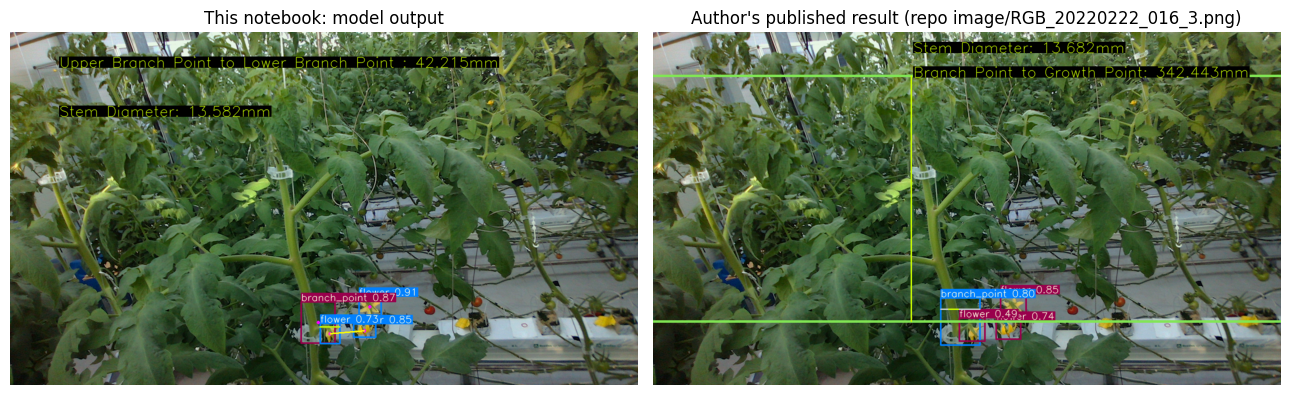

In [ ]:
import cv2, matplotlib.pyplot as plt
ours = cv2.cvtColor(cv2.imread("/content/annotated_result.png"), cv2.COLOR_BGR2RGB)
ref = cv2.cvtColor(cv2.imread("/content/ref/author_result_RGB_20220222_016_3.png"), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
axes[0].imshow(ours); axes[0].set_title("This notebook: model output"); axes[0].axis("off")
axes[1].imshow(ref); axes[1].set_title("Author's published result (repo image/RGB_20220222_016_3.png)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

### 11. Interpretation, validation record, references

**Interpretation.** The measured "Upper Branch Point to Lower Branch Point" distance is the pixel distance between the two lowest branch-point detections converted to mm with the median depth of 5-px crops and the vertical focal length (898.292); the stem diameter uses the authors' RGB-mean stem-pixel clustering and the horizontal focal length (897.507) (`estimate.py:40-85`). Units are millimeters; the working image is the authors' 1280x720 robot capture geometry.

**Validation record (printed below):** runtime device, package versions, pinned commit, checkpoint, sample identity, and the measured values. These are the actual observations of this executed notebook.

**Limitations.** One sample, one run: no claim about dataset-level accuracy; class thresholds/behavior of other checkpoints (`best_tomato.pt`, `best_overall.pt`) were not evaluated; the paper's quantitative tables were not accessible (ScienceDirect blocked automated fetch per the prior investigation); reuse license is unverified (no license file observed in the repository).

**日本語:** 計測値の解釈（ピクセル距離→深度と焦点距離による mm 変換）と、実行環境・検証記録を表示します。単一サンプルであり、論文のデータセット精度の検証にはなりません。

In [ ]:
import torch, cv2, numpy, pandas, subprocess
print("=== Validation record (this run) ===")
print("device:", "GPU: " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("torch:", torch.__version__, "| opencv:", cv2.__version__, "| numpy:", numpy.__version__, "| pandas:", pandas.__version__)
print("author code commit: 97680411699685bb8eb30c86ac01b734d1cecd66")
print("checkpoint: yolor_models/blur21/best_overall.pt (authors' yolor_models.zip, Drive id 14mTBM5oQsalyUQRwluSlE3VLPD4KiMPU)")
print("background-removal mode: blur21 (adapted from main.py's blur100: no blur100 checkpoint shipped)")
print("sample: test/rgb/RGB_20220222_016_3.png + test/depth/dist_20220222_016_3.csv @ pinned commit")
import pandas as pd
print(pd.read_csv("/content/measurements.csv").to_string(index=False))

=== Validation record (this run) ===
device: GPU: Tesla T4
torch: 2.11.0+cu130 | opencv: 4.14.0 | numpy: 2.1.3 | pandas: 2.2.3
author code commit: 97680411699685bb8eb30c86ac01b734d1cecd66
checkpoint: yolor_models/blur21/best_overall.pt (authors' yolor_models.zip, Drive id 14mTBM5oQsalyUQRwluSlE3VLPD4KiMPU)
background-removal mode: blur21 (adapted from main.py's blur100: no blur100 checkpoint shipped)
sample: test/rgb/RGB_20220222_016_3.png + test/depth/dist_20220222_016_3.csv @ pinned commit
                sample  branch_to_branch_mm  stem_diameter_mm
RGB_20220222_016_3.png               42.215            27.164


## References

1. Paper: "Plant growth information measurement based on object detection and image fusion using a smart farm robot", *Computers and Electronics in Agriculture* 207, 107703 (2023). DOI 10.1016/j.compag.2023.107703. Europe PMC AGR/IND607996926.
2. Author code: `kistvision/Plant_growth_measurement` @ commit `97680411699685bb8eb30c86ac01b734d1cecd66` (README, main.py, detect.py, estimate.py, utils/, yolor/).
3. Weights: authors' `yolor_models.zip`, Google Drive id `14mTBM5oQsalyUQRwluSlE3VLPD4KiMPU` (linked from the repository README / weights/README.md); selected entry `yolor_models/blur21/best_overall.pt` — the zip ships no per-crop or blur100 checkpoints, so the blur21 pair was chosen for code/weights consistency (documented adaptation).
4. Sample data: repository `test/rgb/RGB_20220222_016_3.png`, `test/depth/dist_20220222_016_3.csv`, `test/color_depth/dist_20220222_016_3.png`, result reference `image/RGB_20220222_016_3.png` — all at the pinned commit; downloaded only inside this Colab VM.
5. PhenoPaper investigation `p-8efe534069f7288df03a45e7e39be677-20260930T000746Z-3098751` was used as prior research guidance; all scientific facts above were re-verified against the pinned sources.